In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pmdarima as pm
import warnings
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import STL
import statsmodels.api as sm
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('ibb_su_veri.csv') 
df

,_id,Ay,2009.0,2010.0,2011.0,2012.0,2013.0,2014.0,2015.0,2016.0,2017.0,2018.0,2019.0,2020.0,2021.0,2022.0,2023.0,2024.0
0,1,Ocak,55926,60626,65178,67137,71538,74528,77053,80206,81757,84212,83576,84977984,84160554,88812431,90242130,91313882.0
1,2,Şubat,50838,55607,59159,63613,64379,66844,67912,74114,73515,75692,74797,80120814,77068001,80043139,80459071,NaN
2,3,Mart,57261,60690,65895,67727,71663,73786,75459,79147,81215,84274,84666,88457622,85420000,87987877,89652551,NaN
3,4,Nisan,56034,60060,63179,66769,70859,72909,74177,80340,80663,84239,84968,84337847,82501000,87155031,85804024,NaN
4,5,Mayıs,62878,68131,69283,71704,80496,79584,82905,84951,87441,90369,93692,90040181,91395884,95320559,91639400,NaN
5,6,Haziran,65211,65795,72126,77507,79433,80020,82472,88033,87008,90831,93135,90923882,89492561,96060213,94373679,NaN
6,7,Temmuz,66197,68314,76919,83574,84224,84905,88453,88076,93177,95090,96028,98185057,96387379,96961473,103709735,NaN
7,8,Ağustos,66583,75594,75957,80098,82987,83262,89859,91773,91794,93402,94171,98344547,103430618,100430578,103457024,NaN
8,9,Eylül,61154,66734,71906,76396,80163,78215,84083,84767,87630,88053,91987,95694061,95039208,95183779,98550379,NaN
9,10,Ekim,61555,66419,70069,75991,76077,77767,82263,85454,87114,86864,90439,91975770,91950106,95084476,95677961,NaN


In [3]:
df = pd.melt(df, id_vars=['_id', 'Ay'], var_name='Year', value_name='Value')
df['Year'] = df['Year'].astype(str).str.replace('.0', '', regex=False).astype(int)

months = {
    'Ocak': 1,
    'Şubat': 2,
    'Mart': 3,
    'Nisan': 4,
    'Mayıs': 5,
    'Haziran': 6,
    'Temmuz': 7,
    'Ağustos': 8,
    'Eylül': 9,
    'Ekim': 10,
    'Kasım': 11,
    'Aralık': 12,
}

df['month_number'] = df['Ay'].map(months)
df['Date'] = pd.to_datetime(df['Year'].astype(str) + '-' + df['month_number'].astype(str) + '-1')
df = df.set_index('Date').sort_index()
df.index.freq = 'MS'

df.loc[(df['Year'] >= 2009) & (df['Year'] <= 2019), 'Value'] = df.loc[(df['Year'] >= 2009) & (df['Year'] <= 2019), 'Value'] * 1000
df = df.loc[:df['Value'].last_valid_index()]

In [4]:
ts = df[['Value']].copy()
ts['imputed'] = False
ts.loc['2019-12-01', ['Value', 'imputed']] = [np.nan, True]

i = ts['Value']
ratios = []
for year in range(2009, 2024):
    if year == 2019: continue
    december = i[f'{year}-12-01']
    neighbors = (i[f'{year}-11-01'] + i[f'{year + 1}-01-01']) / 2
    ratios.append(december / neighbors)

med = np.median(ratios)

ts.loc['2019-12-01', 'Value'] = med * ((i['2019-11-01'] + i['2020-01-01']) / 2)

clean_ratios = [round(float(r), 2) for r in ratios]

print(f'Ratios for the December divided by Neighbor Average is:{clean_ratios}')
print(f'Median value of the ratio is: {med}')
print(f'Imputed value of the December 2019 data is: {ts.loc["2019-12-01", "Value"]}')

Ratios for the December divided by Neighbor Average is:[1.01, 1.02, 1.03, 1.01, 1.01, 1.01, 1.02, 1.0, 1.01, 1.02, 1.01, 1.01, 1.01, 1.03]
Median value of the ratio is: 1.0139122451264146
Imputed value of the December 2019 data is: 87057032.03586882


In [5]:
print(f'First recorded date is: {ts.index.min()}')
print(f'Last recorded date is: {ts.index.max()}')

print("="*40)

print('Average Tons (m³) of Water Allocated By Year')
print(round(ts.groupby(ts.index.year)['Value'].mean(), 2))

print("="*40)

print('Average Tons (m³) of Water Allocated By Month')
print(round(df.groupby(df.index.month)['Value'].mean(), 2))

print("="*40)

print('Overall Summary')
print(ts.describe())

First recorded date is: 2009-01-01 00:00:00
Last recorded date is: 2024-01-01 00:00:00
Average Tons (m³) of Water Allocated By Year
Date
2009    60304666.67
2010    64835500.00
2011    68645833.33
2012    72744666.67
2013    75787750.00
2014    77037416.67
2015    80429666.67
2016    83218416.67
2017    85053500.00
2018    86747250.00
2019    88438586.00
2020    89511164.75
2021    89499225.42
2022    91972672.42
2023    93088676.33
2024    91313882.00
Name: Value, dtype: float64
Average Tons (m³) of Water Allocated By Month
Date
1     77577748.81
2     69610735.00
3     76886736.67
4     75599660.13
5     82655334.93
6     83494755.67
7     88013376.27
8     88742851.13
9     83703695.13
10    82313354.20
11    78354613.73
12    77429605.00
Name: Value, dtype: float64
Overall Summary
              Value
count  1.810000e+02
mean   8.054748e+07
std    1.131822e+07
min    5.083800e+07
25%    7.212600e+07
50%    8.247200e+07
75%    8.948814e+07
max    1.037097e+08


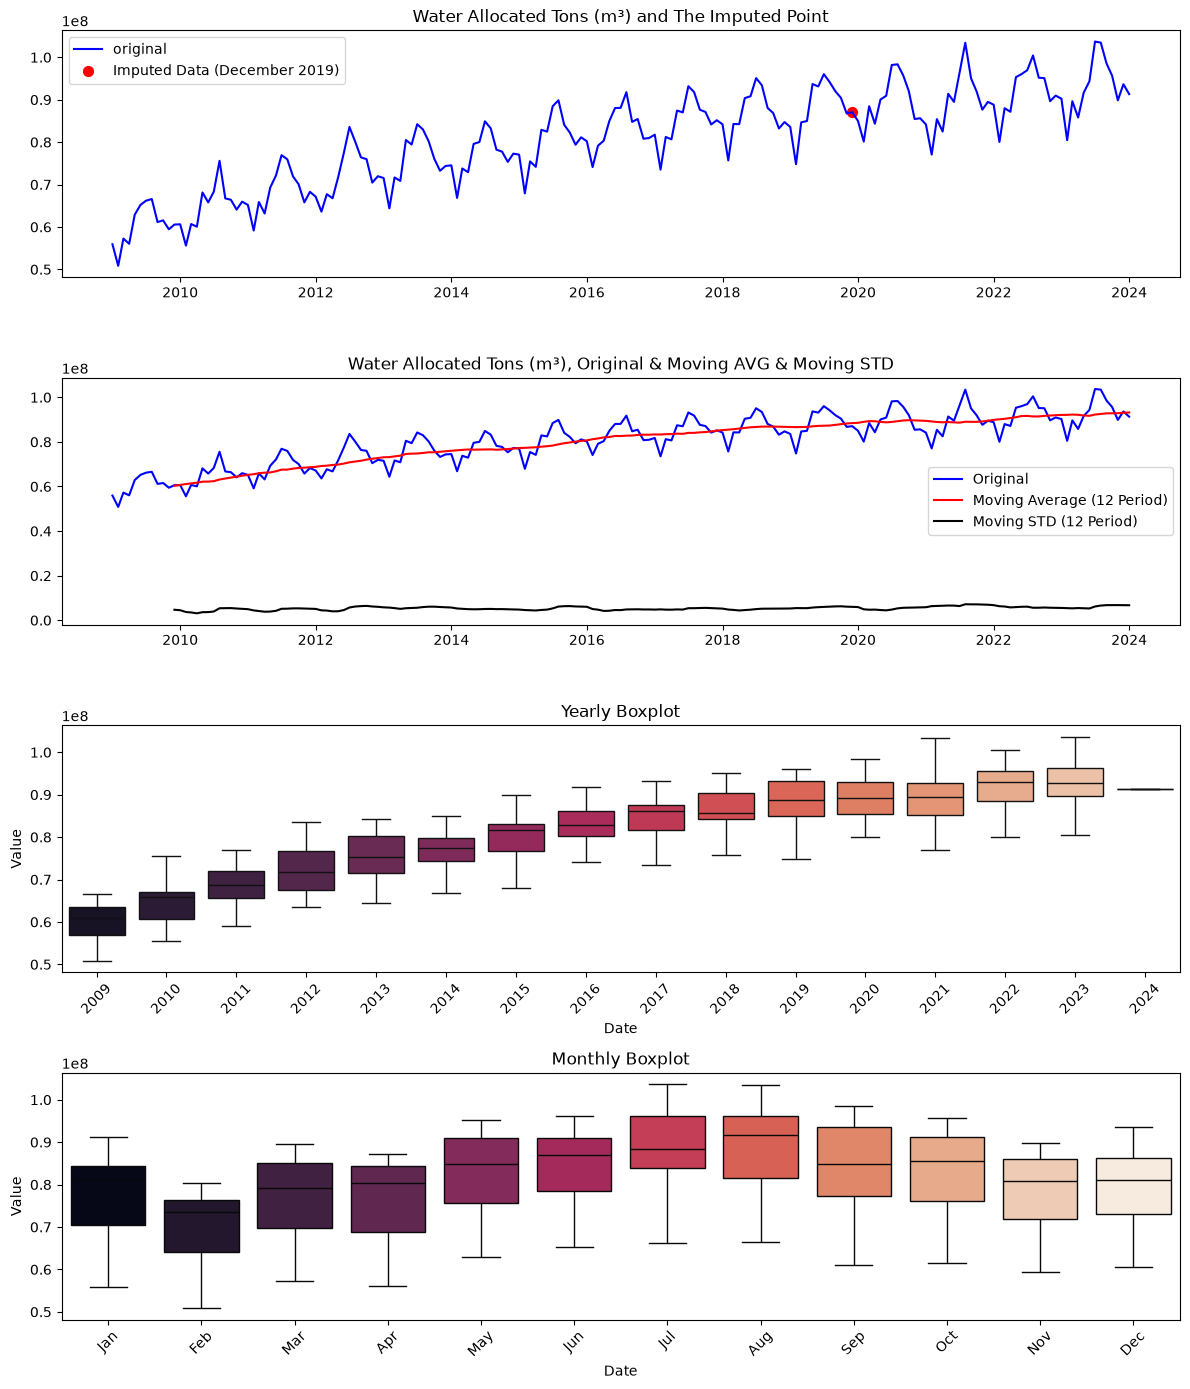

In [6]:
moving_average = ts.rolling(12).mean()
moving_std = ts.rolling(12).std()
imputed_points = ts[
    ts['imputed'] == True]

fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(12, 14))

ax1.plot(ts.index, ts['Value'], color='blue', label='original', linestyle='-',)
ax1.scatter(imputed_points.index, imputed_points['Value'], color='red', s=50, label='Imputed Data (December 2019)')
ax1.set_title('Water Allocated Tons (m³) and The Imputed Point')
ax1.legend()

ax2.plot(ts.index, ts['Value'], color='blue', label='Original')
ax2.plot(moving_average.index, moving_average['Value'], color='red', label='Moving Average (12 Period)')
ax2.plot(moving_std.index, moving_std['Value'], color='black', label='Moving STD (12 Period)')
ax2.set_title('Water Allocated Tons (m³), Original & Moving AVG & Moving STD')
ax2.legend()

sns.boxplot(x=ts.index.year, y=ts['Value'], palette='rocket', legend=False, ax=ax3)
ax3.set_title('Yearly Boxplot')
ax3.tick_params(axis='x', rotation=45)

sns.boxplot(x=ts.index.month, y=ts['Value'], hue=ts.index.month, palette='rocket', legend=False, ax=ax4)
ax4.set_title('Monthly Boxplot')
ax4.set_xticks(range(12))
ax4.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
ax4.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

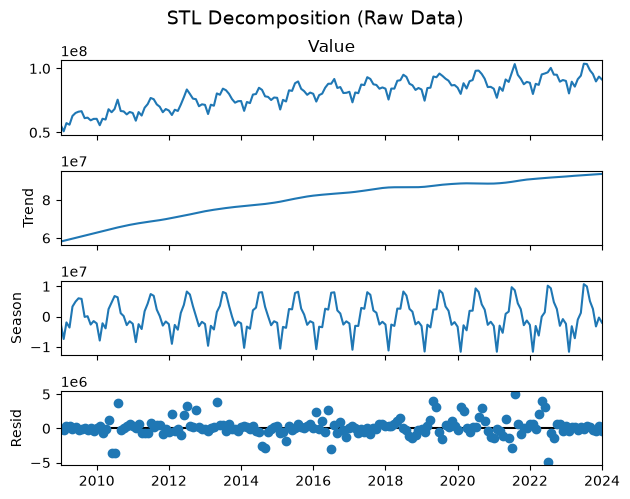

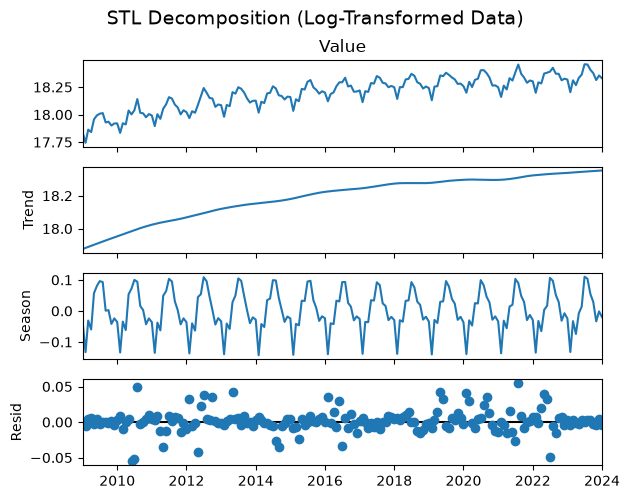

<Figure size 640x480 with 0 Axes>

In [7]:
stl_raw = STL(ts['Value'], period=12, robust=True).fit()
stl_log = STL(np.log(ts['Value']), period=12, robust=True).fit()


fig_raw = stl_raw.plot()
fig_raw.suptitle('STL Decomposition (Raw Data)', fontsize=14, y=1.03)

fig_log = stl_log.plot()
fig_log.suptitle('STL Decomposition (Log-Transformed Data)', fontsize=14, y=1.03)

plt.show()

plt.tight_layout()
plt.show()

In [8]:
for name, stl in [('raw', stl_raw), ('log', stl_log)]:
    s = stl.seasonal
    amp = s.groupby(s.index.year).agg(lambda x: x.max() - x.min())
    print(name, amp.loc[2009:2023].round(3).to_dict())

raw {2009: 13444849.745, 2010: 14678006.851, 2011: 15867588.08, 2012: 17262544.761, 2013: 17769250.53, 2014: 18369251.564, 2015: 18777528.293, 2016: 18765700.447, 2017: 18996768.053, 2018: 19481639.2, 2019: 20233520.696, 2020: 20931290.282, 2021: 21303315.616, 2022: 21816322.987, 2023: 22328009.473}
log {2009: 0.229, 2010: 0.234, 2011: 0.239, 2012: 0.246, 2013: 0.244, 2014: 0.242, 2015: 0.239, 2016: 0.233, 2017: 0.23, 2018: 0.231, 2019: 0.236, 2020: 0.238, 2021: 0.24, 2022: 0.241, 2023: 0.243}


In [9]:
from statsmodels.tsa.stattools import kpss

def stationary_check(x, name, reg):
    x = x.dropna()
    adf = adfuller(x, regression=reg, autolag='AIC')
    kp = kpss(x, regression=reg, nlags='auto')
    print(f'{name} | ADF stat={adf[0]:.3f} p={adf[1]:.3f} lags={adf[2]:.3f} | KPSS stat={kp[0]:.3f} p={kp[1]:.3f}')
    
y = np.log(ts['Value']) 

stationary_check(y, 'log taken', 'ct')
stationary_check(y.diff(), 'd=1', 'c')
stationary_check(y.diff(12), 'D=1', 'c')
stationary_check(y.diff().diff(12), 'd=1, D=1', 'c')

log taken | ADF stat=-2.492 p=0.332 lags=12.000 | KPSS stat=0.384 p=0.010
d=1 | ADF stat=-3.267 p=0.016 lags=14.000 | KPSS stat=0.034 p=0.100
D=1 | ADF stat=-3.114 p=0.026 lags=12.000 | KPSS stat=1.262 p=0.010
d=1, D=1 | ADF stat=-4.373 p=0.000 lags=11.000 | KPSS stat=0.144 p=0.100


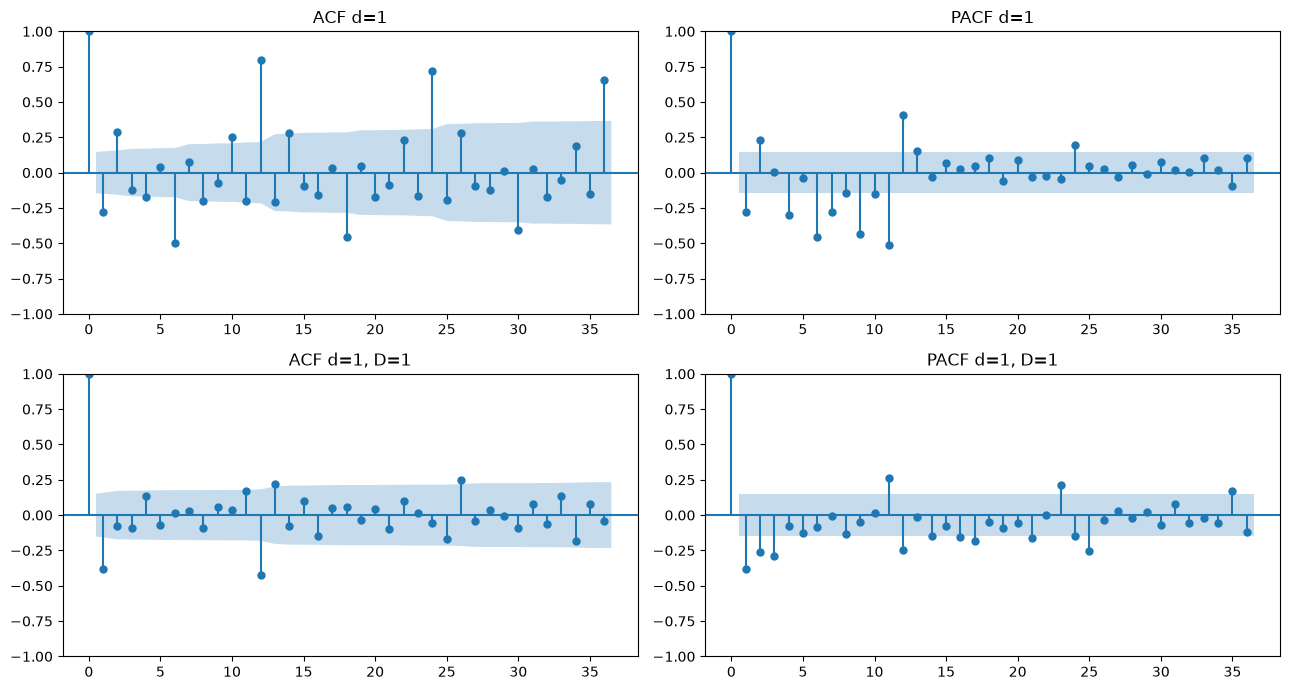

In [10]:
diffs = {'d=1': y.diff().dropna(), 'd=1, D=1':y.diff().diff(12).dropna()}

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for i, (name, d) in enumerate(diffs.items()):
    plot_acf(d, ax=axes[i, 0], lags=36, title=f'ACF {name}')
    plot_pacf(d, ax=axes[i, 1], lags=36, title=f'PACF {name}')

plt.tight_layout()
plt.show()

In [11]:
s = ts['Value']
train = s.loc[:'2021-12-01']
test = s.loc['2022-01-01':]

s_naive = pd.Series(np.tile(train.iloc[-12:].values, 3)[:25], index=test.index)

print('MAE :', round(mean_absolute_error(test, s_naive), 2))
print('RMSE:', round(np.sqrt(mean_squared_error(test, s_naive)), 2))
print('MAPE:', round(mean_absolute_percentage_error(test, s_naive) * 100, 2))

MAE : 3436327.32
RMSE: 3984961.94
MAPE: 3.73


In [12]:
hw = ExponentialSmoothing(train, trend='add', damped_trend=True, seasonal='mul', seasonal_periods=12).fit()

hw_forecast = hw.forecast(25)

print('MAE :', round(mean_absolute_error(test, hw_forecast), 2))
print('RMSE:', round(np.sqrt(mean_squared_error(test, hw_forecast)), 2))
print('MAPE:', round(mean_absolute_percentage_error(test, hw_forecast) * 100, 2))
print(hw.params)

MAE : 1277774.57
RMSE: 1644419.51
MAPE: 1.36
{'smoothing_level': np.float64(0.22273263899267712), 'smoothing_trend': np.float64(0.0), 'smoothing_seasonal': np.float64(0.0), 'damping_trend': np.float64(0.9928843808339326), 'initial_level': np.float64(60149749.99999997), 'initial_trend': np.float64(345335.6060607368), 'initial_seasons': array([0.93423184, 0.84803518, 0.93417442, 0.9179302 , 1.00183307,
       1.00703601, 1.05952248, 1.06376579, 1.00109124, 0.98122714,
       0.9334501 , 0.94633344]), 'use_boxcox': False, 'lamda': None, 'remove_bias': False}


In [13]:
import itertools
import warnings
warnings.filterwarnings('ignore')

results = []
for p, q, P, Q in itertools.product([0, 1 ,2], [0, 1, 2], [0, 1], [0, 1]):
    model = SARIMAX(np.log(train), order=(p, 1, q), seasonal_order=(P, 1, Q, 12)).fit(disp=False)
    fc = np.exp(model.get_forecast(25).predicted_mean)
    results.append({
        'order': (p, 1, q),
        'seasonal': (P, 1, Q, 12),
        'AIC': model.aic,
        'BIC': model.bic,
        'MAE': round(mean_absolute_error(test, fc), 2),
        'RMSE': round(np.sqrt(mean_squared_error(test, fc)), 2),
        'MAPE': round(mean_absolute_percentage_error(test, fc) * 100, 2),
    })

sarimax_results = pd.DataFrame(results).sort_values('AIC')
print(sarimax_results)

        order       seasonal         AIC         BIC         MAE        RMSE  \
17  (1, 1, 1)  (0, 1, 1, 12) -672.520625 -660.669246  1283612.78  1868445.94   
9   (0, 1, 2)  (0, 1, 1, 12) -672.511425 -660.660046  1297624.60  1891641.50   
5   (0, 1, 1)  (0, 1, 1, 12) -672.233065 -663.344531  1357448.99  1968995.54   
11  (0, 1, 2)  (1, 1, 1, 12) -671.282172 -656.467949  1662040.87  2298615.50   
7   (0, 1, 1)  (1, 1, 1, 12) -671.278188 -659.426809  1813092.33  2447861.48   
19  (1, 1, 1)  (1, 1, 1, 12) -670.972320 -656.158097  2033681.47  2703453.52   
29  (2, 1, 1)  (0, 1, 1, 12) -670.512144 -655.697921  1226433.89  1768908.86   
31  (2, 1, 1)  (1, 1, 1, 12) -669.248686 -651.471618  1676628.39  2312556.42   
21  (1, 1, 2)  (0, 1, 1, 12) -668.508590 -653.694367  1345817.46  1954823.21   
33  (2, 1, 2)  (0, 1, 1, 12) -668.407658 -650.630590  1214576.99  1756030.13   
23  (1, 1, 2)  (1, 1, 1, 12) -667.546426 -649.769358  1782589.09  2415522.51   
35  (2, 1, 2)  (1, 1, 1, 12) -667.306905

                                     SARIMAX Results                                      
Dep. Variable:                              Value   No. Observations:                  156
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                 339.117
Date:                            Tue, 20 Oct 2026   AIC                           -672.233
Time:                                    21:05:10   BIC                           -663.345
Sample:                                01-01-2009   HQIC                          -668.621
                                     - 12-01-2021                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.6521      0.079     -8.249      0.000      -0.807      -0.497
ma.S.L12      -0.7899      0.101   

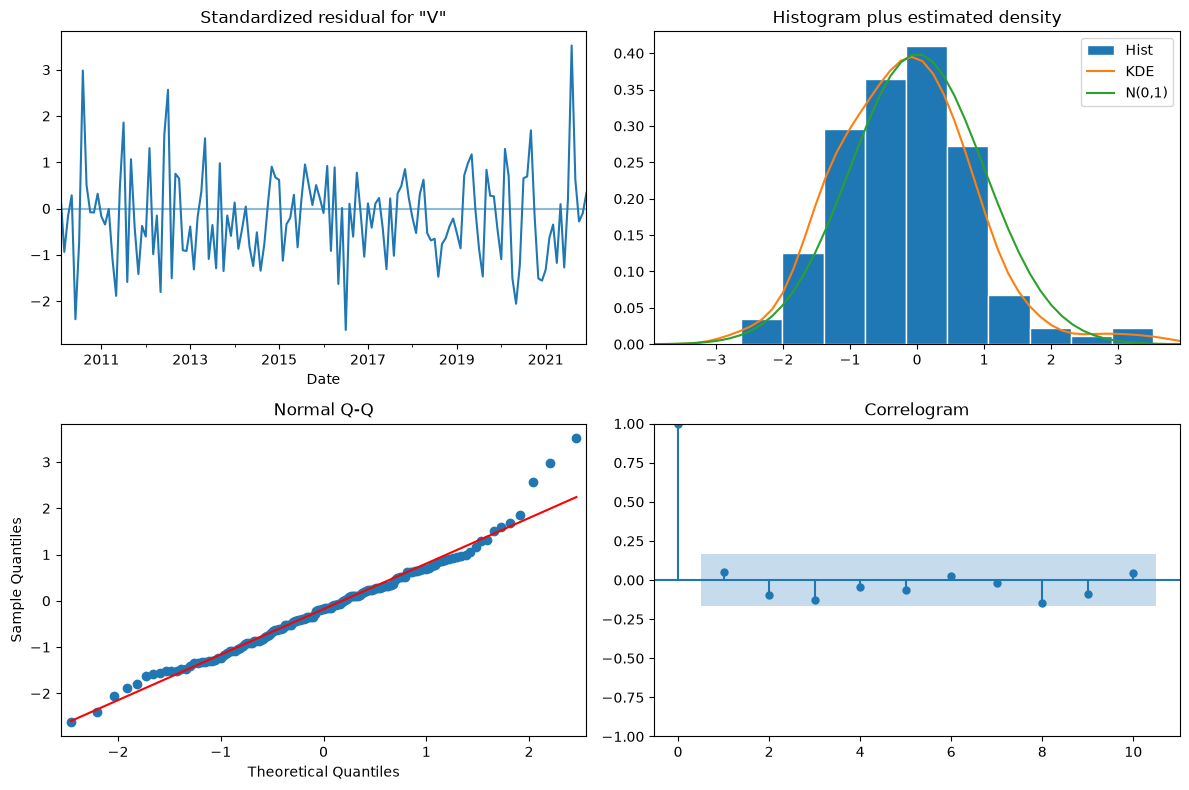

In [14]:
from statsmodels.stats.diagnostic import acorr_ljungbox

best = SARIMAX(np.log(train), order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)

print(best.summary())
best.plot_diagnostics(figsize=(12, 8))
print(acorr_ljungbox(best.resid[13:], lags=[12, 24]))
plt.tight_layout()

In [15]:
resid = best.resid[13:]
print(resid.abs().sort_values(ascending=False).head(5))

Date
2010-08-01    0.082272
2021-08-01    0.076260
2010-06-01    0.066223
2012-07-01    0.058799
2016-07-01    0.057196
dtype: float64


In [16]:
points = [f'{year}-12-01' for year in range(2017, 2023)]
results = []

for p in points:
    i = s.index.get_loc(pd.Timestamp(p))
    tr = s.iloc[:i + 1]
    te = s.iloc[i + 1:i + 13]

    naive = tr.iloc[-12:].values

    hw = ExponentialSmoothing(tr, trend='add', damped_trend=True, seasonal='mul', seasonal_periods=12).fit().forecast(12)

    sarima = np.exp(SARIMAX(np.log(tr), order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False).forecast(12))

    results.append({'points': p, 'Naive': mean_absolute_error(te, naive), 'Holt-Winters': mean_absolute_error(te, hw),
                    'SARIMA': mean_absolute_error(te, sarima)})

performance = pd.DataFrame(results).set_index('points')
print(performance.round(2))
print(performance.mean().round(2))

                 Naive  Holt-Winters      SARIMA
points                                          
2017-12-01  1966583.33    1362160.70  2313142.25
2018-12-01  1946502.67    1422270.74  1172450.06
2019-12-01  2609397.09    1959537.80  2371245.48
2020-12-01  2097098.67    2254548.72  2255943.76
2021-12-01  2973453.67     906318.16   934680.40
2022-12-01  2235787.25    1596484.96  1634691.19
Naive           2304803.78
Holt-Winters    1583553.51
SARIMA          1780358.86
dtype: float64


            Holt-Winters       SARIMA  SARIMA lower 95%  SARIMA upper 95%
2024-02-01    82592175.0   82916159.0        79552391.0        86422159.0
2024-03-01    91129238.0   91790479.0        87856045.0        95901108.0
2024-04-01    89467443.0   89825391.0        85780201.0        94061343.0
2024-05-01    97561375.0   97699736.0        93098271.0       102528631.0
2024-06-01    98365821.0   98542087.0        93706700.0       103626986.0
2024-07-01   103594977.0  104233060.0        98921483.0       109829841.0
2024-08-01   104302791.0  105554591.0        99983921.0       111435635.0
2024-09-01    98393002.0   99953934.0        94503795.0       105718388.0
2024-10-01    96586175.0   98041338.0        92529581.0       103881416.0
2024-11-01    91777171.0   92973542.0        87594358.0        98683063.0
2024-12-01    93341583.0   94790259.0        89155314.0       100781352.0
2025-01-01    92225699.0   93545867.0        87840329.0        99622000.0
2025-02-01    83570577.0   84807419.0 

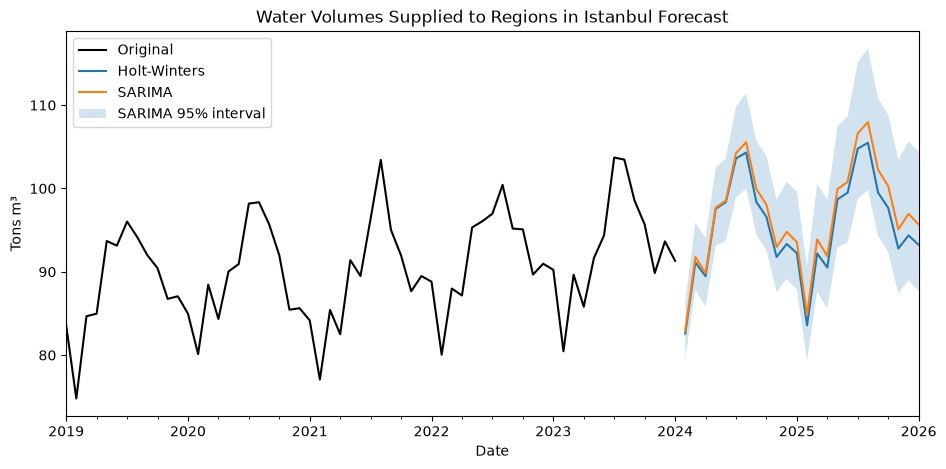

In [17]:
sarima_model = SARIMAX(np.log(s), order=(0,1,1), seasonal_order=(0,1,1,12)).fit(disp=False)
sarima_fc = sarima_model.get_forecast(24)
sarima_perf = np.exp(sarima_fc.predicted_mean)
sarima_ci = np.exp(sarima_fc.conf_int(alpha=0.05))

hw_model = ExponentialSmoothing(s, trend='add', damped_trend=True, seasonal='mul', seasonal_periods=12).fit()
hw_fc = hw_model.forecast(24)

final = pd.DataFrame({'Holt-Winters': hw_fc, 'SARIMA': sarima_perf,
                            'SARIMA lower 95%': sarima_ci.iloc[:, 0],
                            'SARIMA upper 95%': sarima_ci.iloc[:, 1]})
print(final.round(0))

fig, ax = plt.subplots(figsize=(11, 5))
(s.loc['2019':] / 1e6).plot(ax=ax, label='Original', color='black')
(final['Holt-Winters'] / 1e6).plot(ax=ax, label='Holt-Winters')
(final['SARIMA'] / 1e6).plot(ax=ax, label='SARIMA')
ax.fill_between(final.index, final['SARIMA lower 95%'] / 1e6, final['SARIMA upper 95%'] / 1e6, alpha=0.2, label='SARIMA 95% interval')
ax.set_title('Water Volumes Supplied to Regions in Istanbul Forecast')
ax.set_ylabel('Tons m³')
ax.legend()
plt.show()